<a href="https://colab.research.google.com/github/kahrees/the-compendium/blob/main/Matrices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Matrix Properties**

In [3]:
import jax.numpy as jnp

A = jnp.array([[1.0, 2.0],
               [3.0, 4.0]])

print(f"Trace: {jnp.trace(A)}")
print(f"Rank: {jnp.linalg.matrix_rank(A)}")
print(f"Determinant: {jnp.linalg.det(A):.2f}")

Trace: 5.0
Rank: 2
Determinant: -2.00


In [4]:

A = jnp.array([[1.0, 2.0],

[3.0, 4.0]])

A_inv = jnp.linalg.inv(A)
print(f"A * A_inv:\n{A @ A_inv}")

A * A_inv:
[[ 1.0000000e+00  0.0000000e+00]
 [-4.7683716e-07  1.0000002e+00]]


### **Matrix Types**

In [5]:

theta = jnp.pi / 4
Q = jnp.array([[jnp.cos(theta), -jnp.sin(theta)],
               [jnp.sin(theta),  jnp.cos(theta)]])

print(f"Q @ Q.T:\n{Q @ Q.T}")
print(f"Determinant: {jnp.linalg.det(Q):.2f}")

Q @ Q.T:
[[ 9.99999940e-01 -1.26880515e-08]
 [-1.26880515e-08  9.99999940e-01]]
Determinant: 1.00


In [6]:
S = jnp.array([[4.0, 2.0],
               [2.0, 3.0]])

print(f"Symmetric: {jnp.allclose(S, S.T)}")

eigenvalues, eigenvectors = jnp.linalg.eigh(S)
print(f"Eigenvalues: {eigenvalues}")
print(f"Dot product of eigenvectors: {jnp.dot(eigenvectors[:, 0], eigenvectors[:, 1]):.6f}")

Symmetric: True
Eigenvalues: [1.4384472 5.561553 ]
Dot product of eigenvectors: 0.000000


### **Matrix Operations**

In [7]:
A = jnp.array([[1.0, 2.0],
               [3.0, 4.0]])
B = jnp.array([[5.0, 6.0],
               [7.0, 8.0]])

print(f"A @ B:\n{A @ B}")
print(f"B @ A:\n{B @ A}")
print(f"Equal: {jnp.allclose(A @ B, B @ A)}")

A @ B:
[[19. 22.]
 [43. 50.]]
B @ A:
[[23. 34.]
 [31. 46.]]
Equal: False


In [8]:
A = jnp.array([[2.0, 1.0],
               [5.0, 3.0]])
b = jnp.array([4.0, 7.0])

x = jnp.linalg.solve(A, b)
print(f"Solution x: {x}")
print(f"A @ x: {A @ x}")

Solution x: [ 4.9999995 -5.999999 ]
A @ x: [4.       7.000001]


### **Linear Transformations**

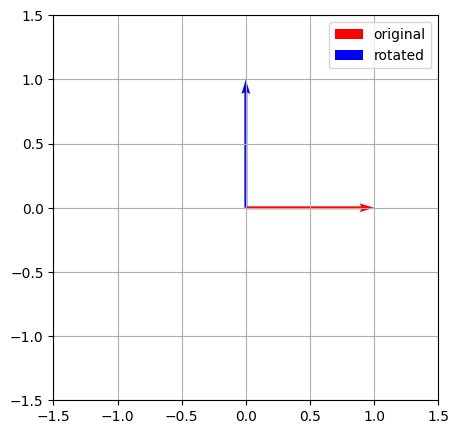

In [9]:
import matplotlib.pyplot as plt

theta = jnp.pi / 2
R = jnp.array([[jnp.cos(theta), -jnp.sin(theta)],
               [jnp.sin(theta),  jnp.cos(theta)]])

v = jnp.array([1.0, 0.0])
v_rot = R @ v  # NumPy's matrix multiplication operator

plt.figure(figsize=(5, 5))
plt.quiver(0, 0, v[0], v[1], angles='xy', scale_units='xy', scale=1, color='red', label='original')
plt.quiver(0, 0, v_rot[0], v_rot[1], angles='xy', scale_units='xy', scale=1, color='blue', label='rotated')
plt.xlim(-1.5, 1.5); plt.ylim(-1.5, 1.5)
plt.grid(True); plt.legend(); plt.gca().set_aspect('equal')
plt.show()

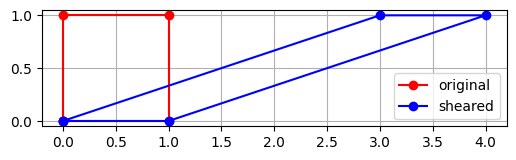

In [10]:
square = jnp.array([[0,0],[1,0],[1,1],[0,1],[0,0]]).T

k = 3
shear = jnp.array([[1, k],
                    [0, 1]])
sheared = shear @ square

plt.figure(figsize=(6, 4))
plt.plot(square[0], square[1], 'r-o', label='original')
plt.plot(sheared[0], sheared[1], 'b-o', label='sheared')
plt.grid(True); plt.legend(); plt.gca().set_aspect('equal')
plt.show()

### **Decompositions**

In [11]:
A = jnp.array([[4.0, 2.0],
               [2.0, 3.0]])

eigenvalues, eigenvectors = jnp.linalg.eigh(A)
print(f"Eigenvalues: {eigenvalues}")
print(f"Eigenvectors orthogonal: {jnp.dot(eigenvectors[:,0], eigenvectors[:,1]):.6f}")

# Reconstruct: A = P D P^T
D = jnp.diag(eigenvalues)
A_reconstructed = eigenvectors @ D @ eigenvectors.T
print(f"Reconstruction matches: {jnp.allclose(A, A_reconstructed)}")

Eigenvalues: [1.4384472 5.561553 ]
Eigenvectors orthogonal: 0.000000
Reconstruction matches: True


In [12]:
import jax.numpy as jnp

A = jnp.array([[4.0, 2.0],
               [2.0, 3.0]])

# Power iteration: finds the LARGEST eigenvalue
v = jnp.array([1.0, 0.0])
for _ in range(20):
    v = A @ v
    v = v / jnp.linalg.norm(v)
print(f"Largest eigenvalue:  {v @ A @ v:.4f}")

# Inverse iteration: multiply by A^{-1} instead of A, finds the SMALLEST eigenvalue
v = jnp.array([1.0, 0.0])
for _ in range(20):
    v = jnp.linalg.solve(A, v)
    v = v / jnp.linalg.norm(v)
print(f"Smallest eigenvalue: {1.0 / (v @ jnp.linalg.solve(A, v)):.4f}")

print(f"jnp.linalg.eigh:    {jnp.linalg.eigh(A)[0]}")

Largest eigenvalue:  5.5616
Smallest eigenvalue: 1.4384
jnp.linalg.eigh:    [1.4384472 5.561553 ]


In [13]:
A = jnp.array([[1.0, 2.0, 3.0],
               [4.0, 5.0, 6.0],
               [7.0, 8.0, 9.0]])

U, S, Vt = jnp.linalg.svd(A)

for k in [1, 2, 3]:
    approx = U[:, :k] @ jnp.diag(S[:k]) @ Vt[:k, :]
    error = jnp.linalg.norm(A - approx)
    print(f"k={k}, reconstruction error: {error:.4f}")

k=1, reconstruction error: 1.0684
k=2, reconstruction error: 0.0000
k=3, reconstruction error: 0.0000
